# Shot maps and expected goals: Florian Wirtz, Bayer Leverkusen 2023/24

This notebook walks through the analysis behind the README:

1. Load every shot from Leverkusen's unbeaten Bundesliga season (StatsBomb Open Data)
2. Engineer basic shot features (location, distance, angle)
3. Profile one player: where he shoots from, chance quality, goals vs xG
4. Put his finishing in context against the squad, and ask how much of it is luck

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import pandas as pd
from IPython.display import Image
from src.data import load_shots, add_features
from src.plots import shot_map, cumulative_xg, squad_comparison, summary

pd.set_option("display.precision", 2)

## 1. Load the data

`load_shots()` downloads every match of the season with `statsbombpy`, keeps only `Shot` events and caches them to `data/`.
StatsBomb released all 34 of Leverkusen's matches, so the file also contains the opponents' shots in those games.

In [2]:
shots = add_features(load_shots(competition_id=9, season_id=281))
print(shots.shape)
shots["team"].value_counts().head()

(916, 28)


team
Bayer Leverkusen    623
VfB Stuttgart        33
Bayern Munich        25
RB Leipzig           24
FSV Mainz 05         23
Name: count, dtype: int64

In [3]:
shots[["minute", "team", "player", "x", "y", "distance", "angle_deg",
       "shot_statsbomb_xg", "shot_outcome", "shot_body_part", "shot_type"]].head()

,minute,team,player,x,y,distance,angle_deg,shot_statsbomb_xg,shot_outcome,shot_body_part,shot_type
0,1,Bayer Leverkusen,Granit Xhaka,92.2,27.1,30.65,13.54,0.02,Saved,Left Foot,Open Play
1,7,RB Leipzig,Timo Werner,107.0,23.2,21.24,13.44,0.04,Off T,Left Foot,Open Play
2,7,Bayer Leverkusen,Jonas Hofmann,96.2,44.8,24.28,18.37,0.04,Off T,Left Foot,Open Play
3,8,RB Leipzig,Ikoma Loïs Openda,101.0,28.8,22.06,17.91,0.02,Blocked,Right Foot,Open Play
4,9,RB Leipzig,Benjamin Henrichs,98.1,29.8,24.16,17.15,0.04,Saved,Right Foot,Open Play


### A quick sanity check on xG

xG should fall as shots get further from goal. The bigger the goal-mouth angle, the better the chance.

In [4]:
np_shots = shots[~shots["is_penalty"]].copy()
np_shots["dist_band"] = pd.cut(np_shots["distance"] * 0.9144, [0, 6, 11, 16, 22, 30, 60],
                               labels=["0-6m", "6-11m", "11-16m", "16-22m", "22-30m", "30m+"])
np_shots.groupby("dist_band", observed=True).agg(
    shots=("is_goal", "size"), conversion=("is_goal", "mean"), mean_xG=("shot_statsbomb_xg", "mean"))

,shots,conversion,mean_xG
dist_band,,,
0-6m,39,0.46,0.40
6-11m,194,0.19,0.17
11-16m,221,0.12,0.12
16-22m,233,0.05,0.06
22-30m,200,0.03,0.03
30m+,21,0.14,0.01


Up to 30 m, mean xG and actual conversion rates line up closely in every band, so the StatsBomb model is well calibrated on this data. The 30 m+ band is the exception: 3 of its 21 shots went in (by Stach, Frimpong and Andrich) against an average xG of 0.01. With a sample that small, a few long-range goals dominate the rate. That's a useful reminder that xG describes averages, not individual shots.

## 2. Player profile: Florian Wirtz

In [5]:
PLAYER, TEAM = "Florian Wirtz", "Bayer Leverkusen"
wirtz = shots[shots["player"] == PLAYER].copy()
pd.Series(summary(wirtz)).round(2)

Shots               71.00
Goals               11.00
xG                   8.47
NP goals            10.00
npxG                 7.69
npxG / shot          0.11
Avg distance (m)    17.25
On target %         47.89
dtype: float64

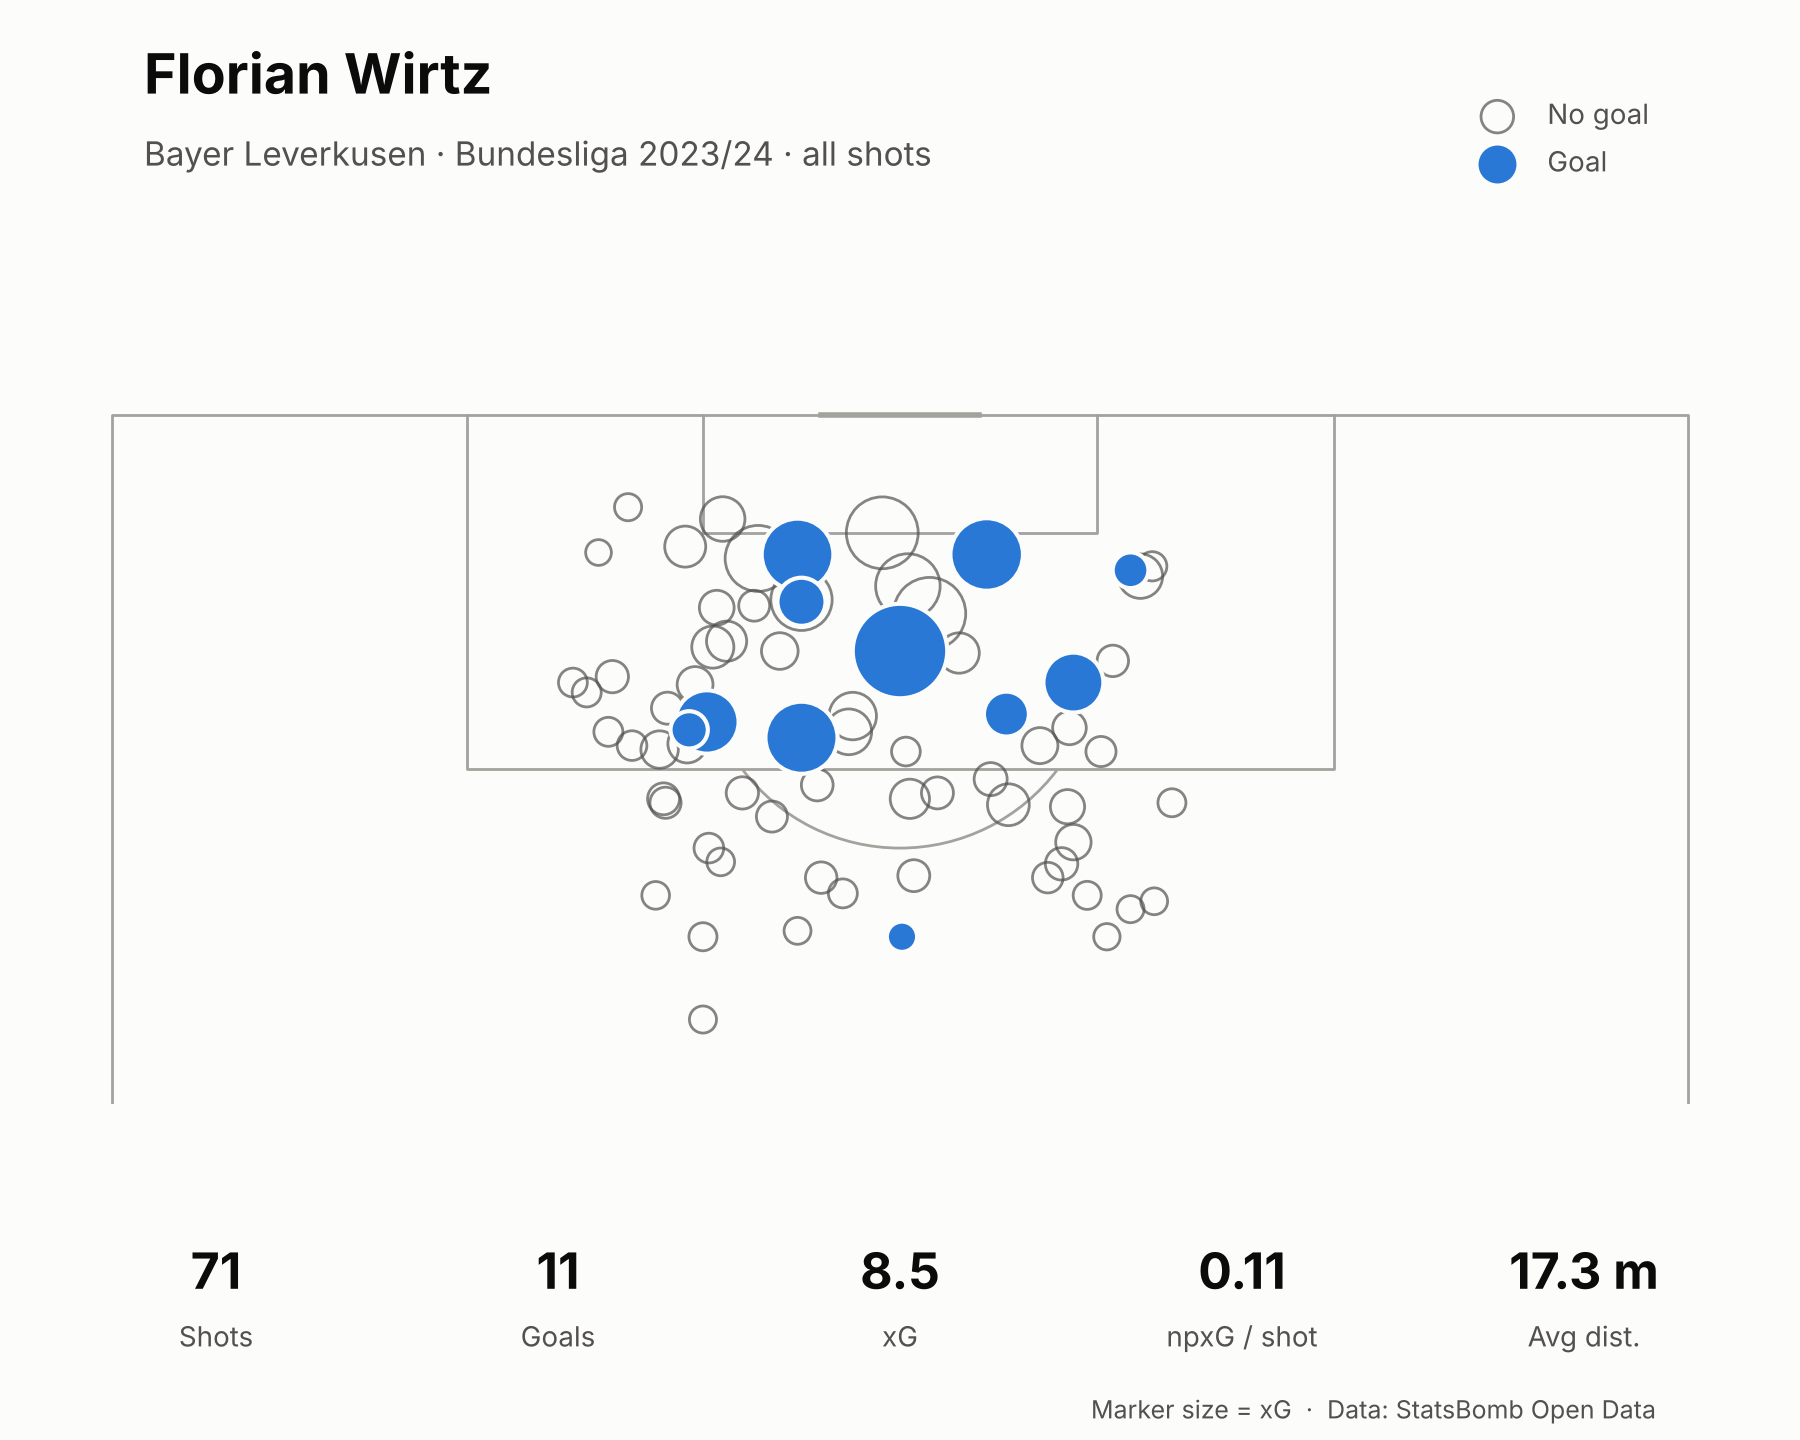

In [6]:
shot_map(wirtz, PLAYER, f"{TEAM} · Bundesliga 2023/24 · all shots", "../figures/florian_wirtz_shot_map.png")
Image("../figures/florian_wirtz_shot_map.png", width=650)

### Inside vs outside the box

The penalty box on StatsBomb's pitch is x ≥ 102 and 18 ≤ y ≤ 62.

In [7]:
w = wirtz[~wirtz["is_penalty"]].copy()
w["zone"] = ((w["x"] >= 102) & w["y"].between(18, 62)).map({True: "Inside box", False: "Outside box"})
w.groupby("zone").agg(shots=("is_goal", "size"), goals=("is_goal", "sum"),
                      npxG=("shot_statsbomb_xg", "sum"), xG_per_shot=("shot_statsbomb_xg", "mean"))

,shots,goals,npxG,xG_per_shot
zone,,,,
Inside box,42,9,6.39,0.15
Outside box,28,1,1.30,0.05


40% of his shots come from outside the box, yet they produce just one goal. The goals come from the box.

### Goals vs xG across the season

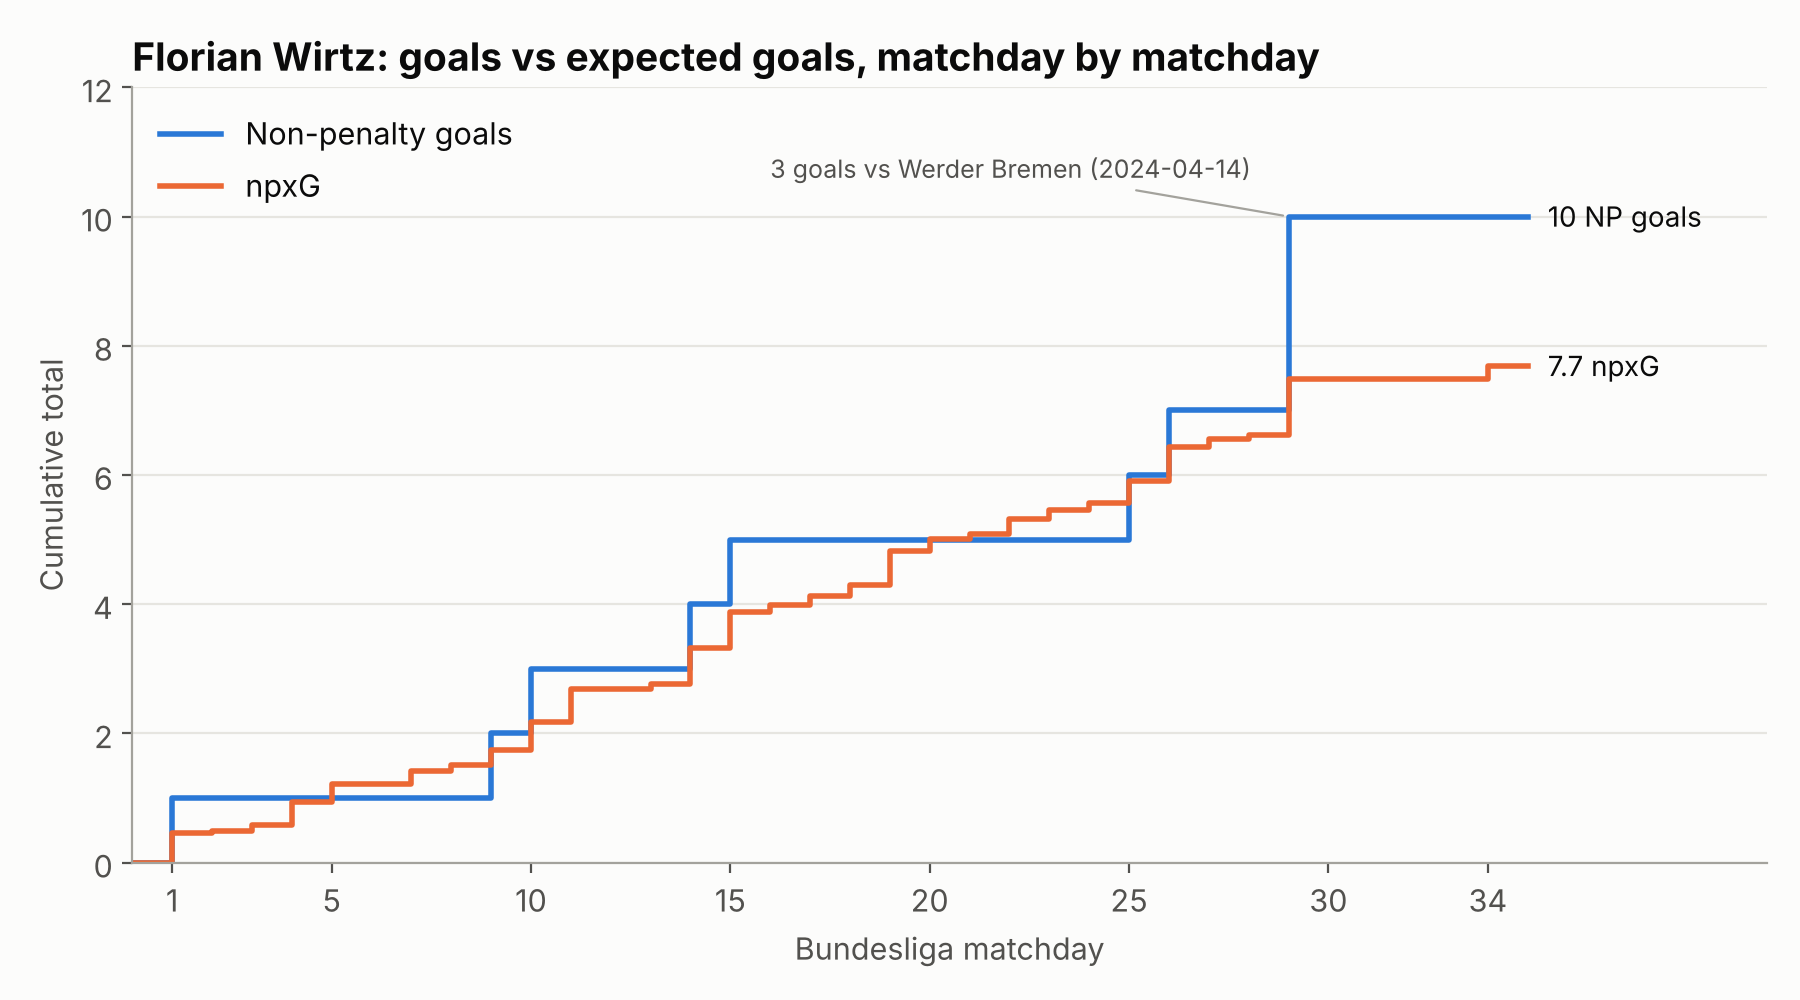

In [8]:
cumulative_xg(wirtz, shots, TEAM, PLAYER, "../figures/florian_wirtz_cumulative_xg.png",
              annotate={"match_id": wirtz.loc[wirtz["away_team"] == "Werder Bremen", "match_id"].iloc[0],
                        "text": "3 goals vs Werder Bremen (2024-04-14)"})
Image("../figures/florian_wirtz_cumulative_xg.png", width=700)

Goals tracked xG closely until matchday 29. That day he scored a hat-trick against Werder Bremen from about 0.77 xG, in the game that clinched the title.

## 3. Squad context, and how much of this is luck?

If each shot is an independent Bernoulli trial with probability = its xG, then

$$\text{Var}(\text{goals}) = \sum_i xG_i\,(1 - xG_i)$$

Dividing *goals − xG* by that standard deviation gives a **z-score**: how unusual the over/under-performance is.

In [9]:
table = squad_comparison(shots, TEAM, PLAYER, "../figures/squad_goals_vs_xg.png")
table

,shots,goals,xg,sd,diff,z
player,,,,,,
Victor Okoh Boniface,77,10,12.84,2.92,-2.84,-0.97
Jeremie Frimpong,56,9,8.72,2.38,0.28,0.12
Florian Wirtz,70,10,7.69,2.42,2.31,0.96
Jonas Hofmann,62,4,5.71,2.13,-1.71,-0.80
Alejandro Grimaldo García,71,10,5.21,1.97,4.79,2.43
Patrik Schick,39,6,4.66,1.91,1.34,0.70
Nathan Tella,21,5,3.76,1.38,1.24,0.90
Amine Adli,27,4,3.09,1.52,0.91,0.60
Adam Hložek,19,2,3.01,1.37,-1.01,-0.74


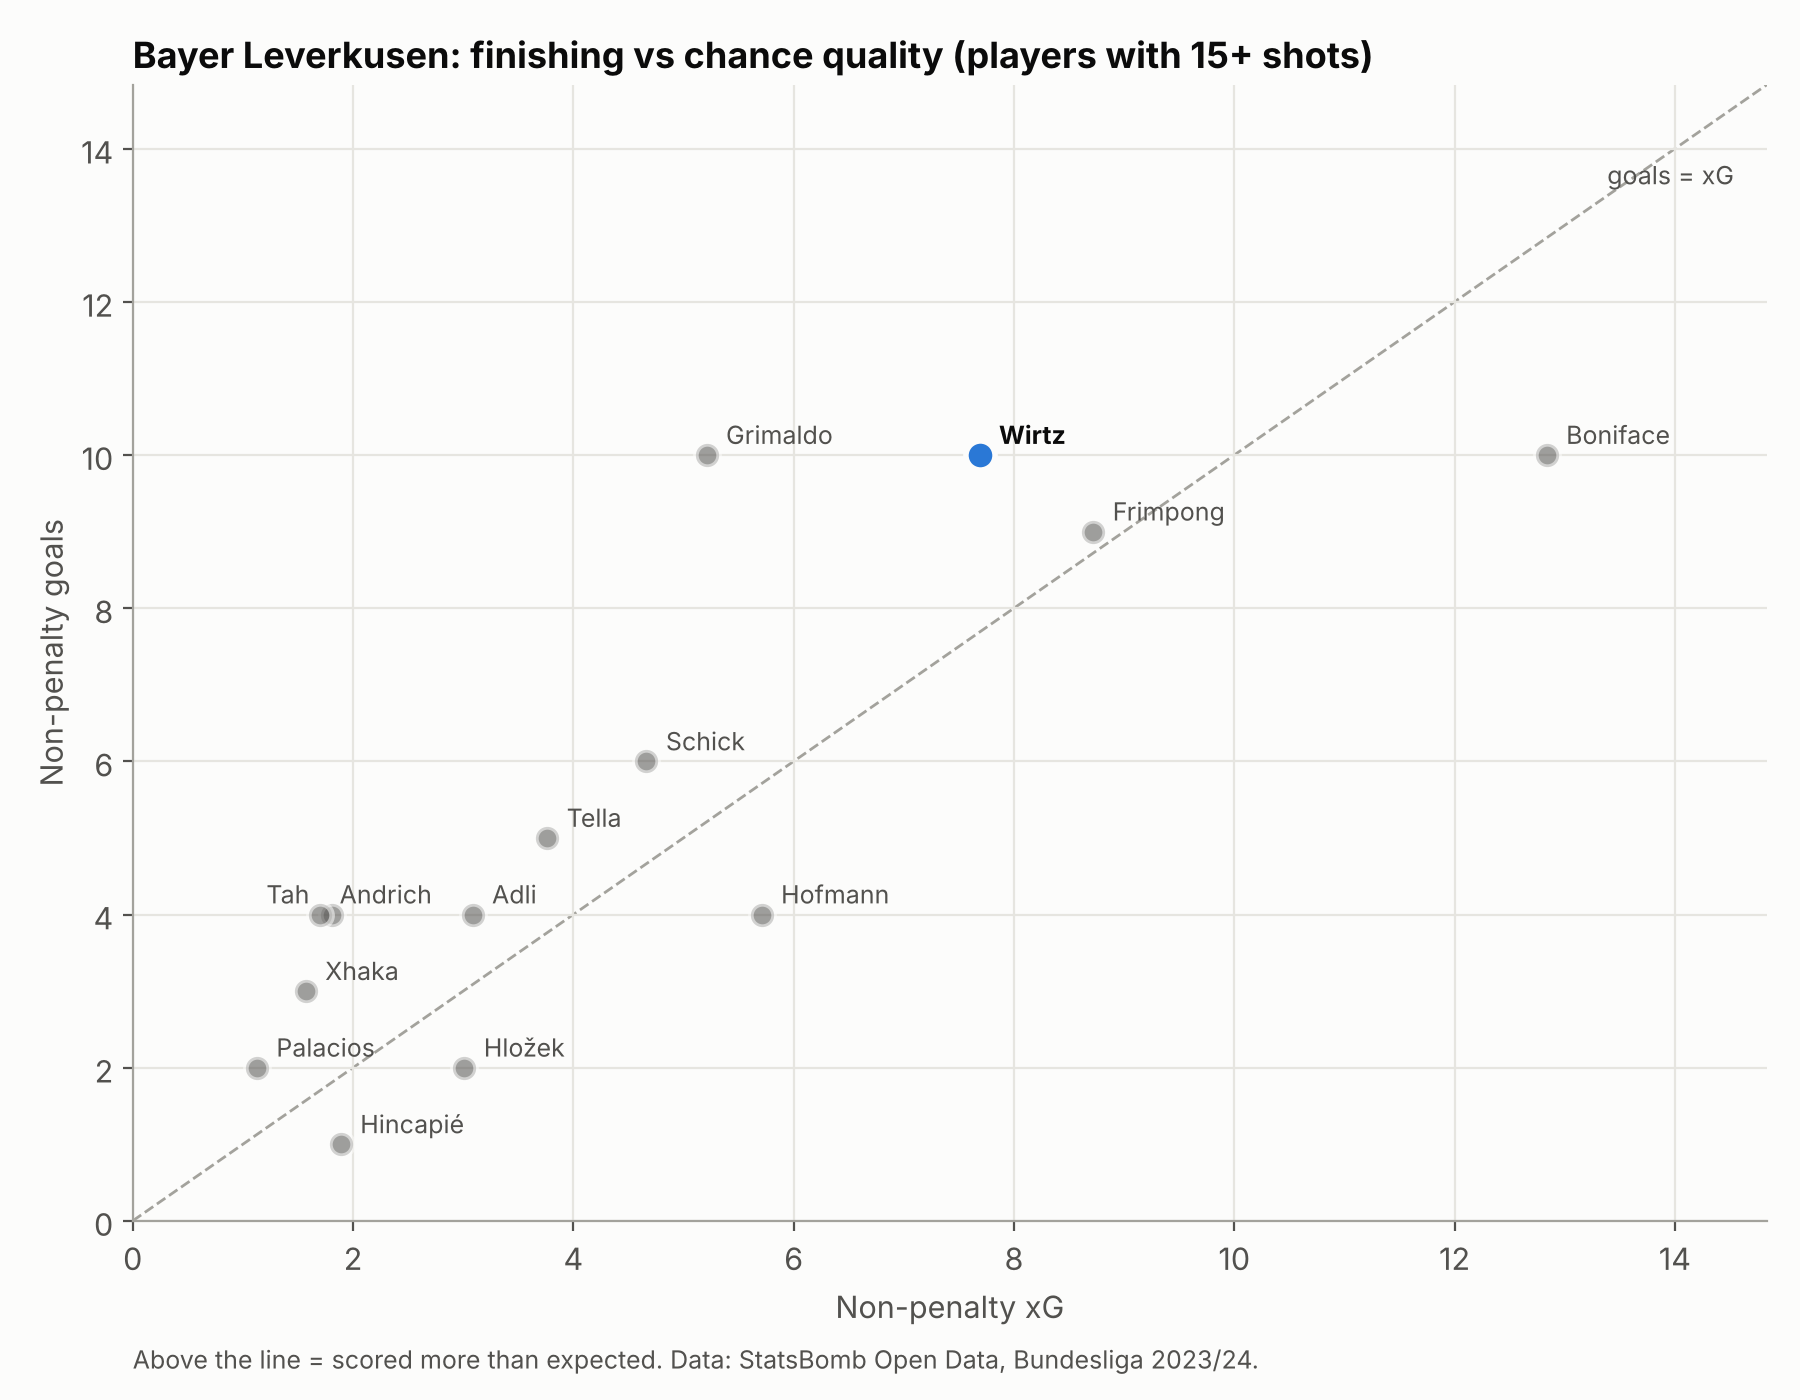

In [10]:
Image("../figures/squad_goals_vs_xg.png", width=650)

- **Wirtz** (z ≈ +1.0) and **Boniface** (z ≈ −1.0) are within normal variation.
- **Grimaldo** (z ≈ +2.4) stands out: a left-back with as many non-penalty goals as the two forwards, from under half the xG.

Is Grimaldo's overperformance just free kicks?

In [11]:
grim = shots[(shots["player"] == "Alejandro Grimaldo García") & ~shots["is_penalty"]]
grim.groupby("shot_type").agg(shots=("is_goal", "size"), goals=("is_goal", "sum"), xG=("shot_statsbomb_xg", "sum"))

,shots,goals,xG
shot_type,,,
Free Kick,18,2,0.93
Open Play,53,8,4.28


Only partly: 2 goals from 0.9 xG on direct free kicks, but 8 goals from 4.3 xG in open play.

## Takeaways

- Wirtz's chance quality (0.11 npxG/shot) reflects an attacking midfielder who shoots from range a lot. His goals come from inside the box.
- His +2.3 overperformance is roughly one standard deviation and heavily concentrated in one match, so it's not strong evidence of elite finishing.
- Grimaldo's +4.8 (2.4 SD) is the squad's real outlier and worth tracking in a later season.

**Next step:** train my own xG model on this data and compare it with StatsBomb's (Project 4).